<div align="center">

# CA5 Clustering 🚀

**Clustering computer assignment**

👤 **Author:** Sadegh Samadi  |  📅 **Date:** 2025-6-12  |  📄 **SSID:** 810102588

</div>


## 🔖 Table of Contents
1. [Libraries](#libraries)
2. [Load and Preprocess Data](#load-and-preprocess-data)
3. [Extract Features](#extract-features)
4. [K-Means And Elbow](#k-means-clustering-and-the-elbow-method)
5. [DBSCAN](#dbscan-clustering)
6. [Hierarchical](#hierarchical-agglomerative-clustering)
7. [Dimensionality Reduction](#dimensionality-reduction)
8. [Evaluation](#evaluation)
9. [Analysis](#analysis)

## ❓ Table of Q&A
1. [Why Preprocessing](#1-lowercasing)
2. [Supervised vs UnSupervised](#1-supervised)
3. [Why Features](#feature-vector)
4. [Explanations Of Algorithms](#1-k-means)
5. [Text Feature Vectorization Methods](#1-one-hot-encoding)
6. [Sentence Transformer & all-MiniLM-L6-v2?](#sentence-transformer)
7. [Elbow Method](#elbow-method)
8. [PCA](#pca)
9. [Silhouette & Homogeneity Score](#silhouette-score)





---
## Libraries

In [71]:
import pandas as pd
import re 
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
from sentence_transformers import SentenceTransformer
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score


---

## Load and Preprocess Data

In [72]:
df = pd.read_csv('musicLyrics.csv')
print(df.shape)
#nltk.download()

(2999, 1)


In [73]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))
def preprocess(text):
    text = text.lower()
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^a-z\s]', '', text) 
    tokens = word_tokenize(text)
    lemmaTokens = []
    for token in tokens:
        if (token not in stop_words and token.isalpha()):
            lemmaTokens.append(lemmatizer.lemmatize(token))
    return " ".join(lemmaTokens)
df['cleanLyric'] = df['Lyric'].fillna("").apply(preprocess)

### ❓ **Why this method for preprocessing? and why preprocessing?**

>#### **1. Lowercasing**
>- *because there is no difference between small and capital letters and it reduces the variety of characters*
>#### **2. Digit Deletion**
>- *In my idea digits aren't meaningful in lyrics usually they are used to show the number of verse*
>#### **3. Remove Punchtuation**
>- *the reason is similar to number one*
>#### **4. tokenizing**
>- *Splits the text into individual words and removes consecutive spaces*
>#### **5. Removing Stop Words**
>- *These are extremely common words that don’t help distinguish one lyric from another and also reduce vocabulary size and noise*
>#### **6. Lemmatization**
>- *Reduce words to their base form (“running” to “run”) so all variants share one representation.*

>### **Summary of the reasons of text preprocessing**
>#### *1. Reduces Noise And Normalizing*
>#### *2. Reduces Vcabulary Size*
>#### *3. Improve Consistency Across Samples*
>#### *4. Tokenize (Prepare Data For Main Process)*
>#### *5. Eliminate useless words like stopwrods*







---

## Extract Features

In [74]:
model = SentenceTransformer('all-MiniLM-L6-v2')
features = model.encode(df['cleanLyric'].tolist(), show_progress_bar = True)
print(features.shape)

KeyboardInterrupt: 


---

## K-Means Clustering And The Elbow Method

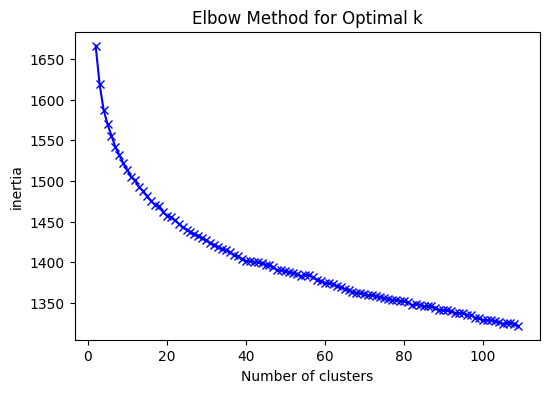

In [75]:
inertias = []
kRange = range(2, 110)
for k in kRange:
    KM = KMeans(n_clusters = k, init = 'k-means++', random_state = 42)
    KM.fit(features)
    inertias.append(KM.inertia_)

plt.figure(figsize=(6,4))
plt.plot(kRange, inertias, 'bx-')
plt.xlabel('Number of clusters')
plt.ylabel('inertia')
plt.title('Elbow Method for Optimal k')
plt.show()

In [158]:
optimalK = 4
finalKM = KMeans(n_clusters = optimalK, init = 'k-means++', random_state = 42)
KMeansLabels = finalKM.fit_predict(features)
df['KMean'] = KMeansLabels


---

## DBSCAN Clustering

In [159]:
dbscan = DBSCAN(eps = 1.1, min_samples = 2, metric = 'euclidean')
dbscanLabels = dbscan.fit_predict(features)
df['DBSCAN'] = dbscanLabels
n_clusters = len(set(dbscanLabels)) - (1 if -1 in dbscanLabels else 0)
n_noise = list(dbscanLabels).count(-1)

print("Estimated number of clusters: ", n_clusters)
print("Estimated number of noise points: ", n_noise)

Estimated number of clusters:  2
Estimated number of noise points:  7



---

## Hierarchical (Agglomerative) Clustering

In [175]:
hier = AgglomerativeClustering(n_clusters = optimalK, linkage = 'ward')
hierLabels = hier.fit_predict(features)
df['hier'] = hierLabels

### ❓ **Supervised vs Unsupervised**

>#### **1. Supervised**
>- *Supervised learning trains models on labeled data (with known outputs)*
>#### **2. UnSupervised**
>- *unsupervised learning (like clustering) works on unlabeled data to find hidden patterns or groupings. In clustering, we do not use any ground-truth label but rely on the structure of the data itself. This makes clustering useful for exploratory analysis and tasks where labels are unavailable*

>### **Summary of comparing**

<div align="center">

>| Feature                     | Supervised Learning                                                     | Unsupervised Learning                           |
>|-----------------------------|-------------------------------------------------------------------------|-------------------------------------------------|
>| Data requirement            | `Labeled data`                                                          | `Unlabeled data`                                |
>| Main goal                   | `Predict outcome (classification/regression)`                           | `Discover structure/patterns`                   |
>| Examples                    | `Spam detection, sentiment analysis`                                    | `Clustering, topic modeling, PCA`               |
>| Algorithms                  | `Linear Regression, Decision Tree`                                      | `K-Means, DBSCAN, Hierarchical Clustering`      |
>| Evaluation                  | `Easy (use accuracy, F1, etc.)`                                         | `Hard (no ground truth)`                        |
>| Complexity of labeling      | `Expensive (manual labels needed)`                                      | `Cheap (no labels needed)`                      |

</div>

### ❓ **Why Feature Vector?**
>### **Feature vector**
>- *feature vector is simply a list of features assembled into one object. Here we uses model `all-MiniLM-L6-v2` to extract (384) features.*

>### **Why Feature?**
>-*If we didn't extract features, we cannot feed raw data (text) directly into the clustering models. We need to trasnform that data into a numerical form. After transforming we can:*
>- *1. Feed models with feature vectors* 
>- *2. Do mathematical operation*
>- *3. Reduce Dimensionality and visualization*


### ❓ **Explainations Of Algorithms**
>### **1. K-Means**
>- *K-Means is a centroid-based clustering algorithm. It partitions data into k(which we should determine before running the algorithm) clusters by repeatedly assigning each point to the nearest centroid, then recalculating centroids as the mean of each cluster.*
>### **2. DBSCAN**
>- *DBSCAN builds clusters based on density. Core points with at least `min_samples` in their ε-neighborhood and expands clusters from those core points. Choosing `ε` and `min_samples` is one of the challenges about this algorithm. Also it is able to handles noises.*
>### **3. Hierarchical Clustering**
>- *Starts with each point as its own cluster, merging pairs step by step based on a linkage criterion. There are differet linkage criterions:*

<div align="center">

> | **Linkage Method** | **Merge Criterion**                        |
> | ------------------ | ------------------------------------------ |
> | Single             | Minimum inter-point distance               |
> | Complete           | Maximum inter-point distance               |
> | Average            | Mean inter-point distance                  |
> | Centroid           | Distance between cluster centroids         |
> | Ward               | Minimum variance increase (sum-of-squares) |

</div>

> ### **Summary of comparing**
<div align="center">

> | Algorithm     | Specify *k*? | Shape of clusters | Handles noise? |
> | ------------- | ------------ | ----------------- | -------------- |
> | K‑Means       | ✅ Yes        | Spherical/convex  | ❌ No           |
> | DBSCAN        | ❌ No         | Any shape         | ✅ Yes          |
> | Hierarchical | ❌ No         | Varies by linkage | ❌ No           |


</div>

### ❓ **What Are Text Feature Vectorization Methods?**
>### **1. One-Hot Encoding**
>- *Represents each word by a binary vector where one position corresponds to that word in the vocabulary.*
>- **Pros:**
> >- *Very simple, intuitive.*
> >- *Works for small vocabularies and basic tasks.*
>- **Cons:**
> >- *Extremely high-dimensional & sparse.*
> >- *Doesn’t capture semantics or context—every word is independent.*

>### **2. Bag Of Words**
>- *Counts how many times each word appears in a document (ignoring order)*
>- **Pros:**
> >- *Simple, interpretable, widely used in classification & similarity tasks.*
>- **Cons:**
> >- *High-dimensional and sparse.*
> >- *Loses word order and semantics.*

>### **3. Word2Vec**
>- *Learns dense, lower-dimensional vectors for words (using CBOW or Skip-gram models), capturing semantic similarity.*
>- **Pros:**
> >- *Compact representations, good for modeling semantics.*
>- **Cons:**
> >- *Fails with polysemy and context.*
> >- *Struggles with out-of-vocabulary words.*

>### **4. Transformer Embeddings**
>- *Deep contextualized embeddings for words, sentences, or documents.*
>- **Pros:**
> >- *Each token's representation depends on its context.*
>- **Cons:**
> >- *Computation-heavy, large model sizes.*
> >- *More complex to fine-tune and use effectively.*


### ❓ **What Are Sentence Transformer & all-MiniLM-L6-v2?**
>### **Sentence Transformer**
> >- *A high-level framework built on top of Hugging Face Transformers, designed to produce semantically meaningful embeddings from sentences or paragraphs. Commonly used for tasks like semantic search, clustering, and paraphrase detection.*
>### **all-MiniLM-L6-v2**
> >- *all-MiniLM-L6-v2 has architecture based on MiniLm. It is a 6-layer transformer model with 384-dimensional hidden states which dreived from MiniLM-v2. It is optimized for sentencee and short paragraph embedding. It's efficent in size and fast and also ideal for semantic search, clustering, sentence simliarity tasks.*

### ❓ **What Is Elbow Method In K-Means?**
>### **Elbow Method**
> >- *The elbow method is a technique used to determine the optimal number of clusters (k) in K-Means clustering. First we define a range for k. Then run means for different values in that range and storing inertia. After computing all inertias, plot k vs inertias. The inertia decreases as k increases, but after a point, the improvement slows down forming an `Elbow` **shape** in the graph. That point is our optimal k.*



### ❓ **What Is PCA?**
>### **PCA**
> >- *PCA is a dimensionality reduction technique. it transforms high-dimensional data into a lower-dimensional space while keeping the most important information. we use PCA to reduce data into 2D data then we are able to visualize our clustering. PCA finds the directions (Principal components) where the data veries the most. It helps to keep the most meaningful structure of data.*


---

## Dimensionality Reduction

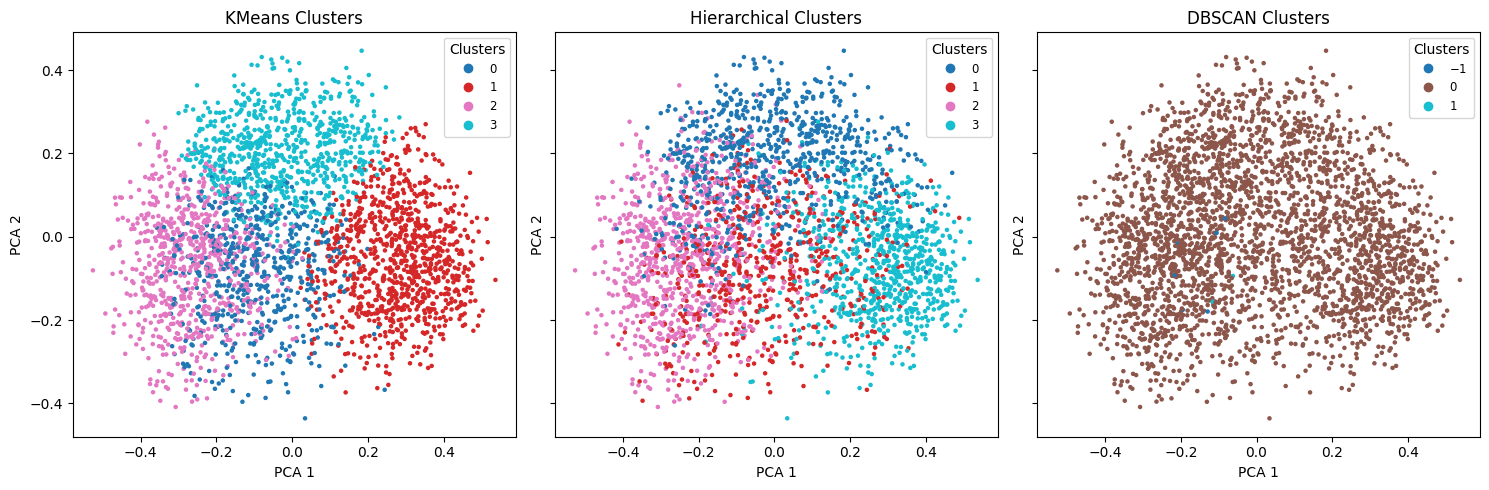

In [176]:
pca = PCA(n_components = 2)
features2D = pca.fit_transform(features)

labelsList = [('KMeans', KMeansLabels), ('Hierarchical', hierLabels), ('DBSCAN', dbscanLabels)]
fig, axes = plt.subplots(1, 3, figsize = (15, 5), sharex = True, sharey = True)
for ax, (name, labels) in zip(axes, labelsList):
    sc = ax.scatter(features2D[:, 0], features2D[:, 1], c = labels, cmap = 'tab10', s = 5)
    ax.set_title(f"{name} Clusters")
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")
    ax.legend(*sc.legend_elements(), title = "Clusters", loc = 'upper right', fontsize = 'small')

plt.tight_layout()
plt.show()

## ❓ **What are Silhouette & Homogeneity Score?**
>### **Silhouette Score**
>
>The **Silhouette Score** quantifies how well-separated the clusters are and how appropriately each data point fits into its assigned cluster. It is computed for each data point and then averaged over all points.
>
>The formula for the silhouette value S(i) for a single data point i is:
>
>$$
>S(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}}
>$$
>
>Where:
>- **a(i)** is the mean distance between the point i and all other points in the same cluster (capturing cohesion).
>- **b(i)** is the minimum mean distance from the point i to all points in any other cluster (capturing separation).
>
>**Interpretation:**
>- **S(i) close to +1:** The data point is well-matched to its own cluster and distinctly separated from other clusters.
>- **S(i) around 0:** The data point lies near a cluster boundary, meaning it could conceivably belong to another cluster.
>- **S(i) close to -1:** The data point might be assigned to the wrong cluster, being closer on average to a neighboring cluster than its own.
>
>This metric is particularly valuable because it evaluates clustering quality purely based on distances between points, without requiring ground-truth labels.
>
>---
>
>### **Homogeneity Score**
>
>The **Homogeneity Score** is used when ground-truth labels are available. It assesses whether each cluster contains only members of a single class.
>
>The formula for the Homogeneity Score is:
>
>$$
>H = 1 - \frac{H(C|K)}{H(C)}
>$$
>
>Where:
>- **H(C)** is the entropy of the true class labels.
>- **H(C|K)** is the conditional entropy of the class labels given the cluster assignments.
>
>**Interpretation:**
>- **Score = 1:** Perfect homogeneity — every cluster contains only data points from a single class.
>- **Score = 0:** Poor homogeneity — clusters mix members from different classes without any clear separation.
>
>---
>
>### **Summary**
>
>- **Silhouette Score**: Provides an unsupervised evaluation of how tightly clustered the data points are and how well-separated the clusters are based solely on the distances between points. Therefore we can use this metric to evaluate how good our models are...
>- **Homogeneity Score**: Offers a supervised evaluation by measuring how well the clusters align with the ground-truth class labels, emphasizing the purity of each cluster. But here we don't have any real labels, Therefore we can't use this metric.


---

## Evaluation

In [177]:
SKMeans = silhouette_score(features, KMeansLabels)
SDBSCAN = silhouette_score(features, dbscanLabels)
SHier = silhouette_score(features, hierLabels)
print(f"Silhouette Scores: K-Means={SKMeans:.3f}, DBSCAN={SDBSCAN:.3f}, Hierarchical={SHier:.3f}")

Silhouette Scores: K-Means=0.049, DBSCAN=0.146, Hierarchical=0.032


In [ ]:
for method, labels in [('K-Means', KMeansLabels), ('DBSCAN', dbscanLabels), ('Hierarchical', hierLabels)]:
    print(f"\n {method} samples ")
    for cid in sorted(set(labels)):
        if cid == -1: continue
        cluster_lyrics = df.loc[labels == cid, 'Lyric'].dropna()
        n = min(2, len(cluster_lyrics))
        samples = cluster_lyrics.sample(n=n, random_state=42).values
        print(f"Cluster {cid}:")
        for s in samples:
            print(" -", s.replace('\n',' ')[:150], "…")


 K-Means samples 
Cluster 0:
 - [Intro movie samples] Man you know there used to be rules to this shit Nowadays people do whatever the FUCK they want And worry about that shit later  …
 - Jump on the tube Just to see you My hearts in a tunnel baby what can I do? So walk it off and plant your seed You take me over there is that just what …
Cluster 1:
 - [Verse 1] The Eastern world it is explodin Violence flarin and bullets loadin Youre old enough to kill but not for votin You dont believe in war, so w …
 - [Verse 1] Standing two steps down I fell into the hole in the ground You can make the plan [Verse 2] When the tapes rewound By the time you call the b …
Cluster 2:
 - The only thing constantly changing is change And change is always for the worse The worm on the hook always eaten by a fish The fish by bird man or wo …
 - [Verse 1] Terrain disfigured Pressure temple, tempt to tap trigger Must contend with this diseased mind and drown liver Cradle soul eternal type land  …
Cluster 3:
 


---

## Analysis

>### **K-Mean Clusters**
> >- *Cluster 0: Maybe its a category of cinematic musics*
> >- *Cluster 1: In this cluster we the vocabulary in common about war or violence*
> >- *Cluster 2: According to the meaning, i guess they are about negative changes and decays*
> >- *Cluster 3: They're about first-person feelings*

>### **DBSCAN Clusters**
> >- *Cluster 0: They look like a rap music.*
> >- *Cluster 1: Both of the samples are related to films and cinema*

>### **Hierarchical Clusters**
> >- *Cluster 0: They seem to be kind of energy boost musics*
> >- *Cluster 1: I think they are related to society.*
> >- *Cluster 2: I'm not sure but i guess these lyrics has dark theme.*
> >- *Cluster 3: They didn't look like a music. They are like some playful shoutouts because of the greeting and announcing their nicknames*

>## Final Conclusion
> >- *First of all accroding to the `Silhouette Score`, we expected that DBSCAN has the best clustering performance among other algorithms and after that KMeans and Hierarchical*
> >- *For Hierarchical i used all different linkages but i got sensible result with `ward` linkage with lower score rather than other linkages. other linkages has clusters 1, 2, 3 with lenght of 1 data which i think is not a valid clustering.*
> >- *According to the Samples of each cluster, i think detecting rap music in DBSCAN is a perfect result. Also there are some good categories in other algorithms. But also let's take a look at clustering graphs;*

>- ### **K-Means Graph**
> >- *As we can see there is heavy overlap and it can't clusterize some classes properly... for example there is no clean boundary between cluster 0 with others especially cluster 2*

>- ### **Hierarchicall Graph**
> >- *There’s no clear border between clusters and it causes overlaping between clusters... and the shape of clusters look like an oval.*

>- ### **DBSCAN Graph**
> >- *Almost everything is in cluster 0. There are few noises and there are 2 clusters*

>- *I think if we want to say which one is better clustering algorithm in this assignment, we can't say only one of them and it depends on what we want.. if we want 4 or 5 clusters, obviously DBSCAN fails. On the other hand, if we want good separation, according to the `Silhouette Score` DBSCAN wins..*